In [3]:
import statsmodels.api as sm
import pandas as pd


In [ ]:
# Filtered dataset containing weekly sales on holidays and non holidays
weekly_df = pd.read_csv('../data/walmart_weekly_cleaned.csv')

In [21]:
weekly_df

,date,weekly_sales,holiday_flag
0,2010-02-05,49750740.50,0
1,2010-02-12,48336677.63,1
2,2010-02-19,48276993.78,0
3,2010-02-26,43968571.13,0
4,2010-03-05,46871470.30,0
...,...,...,...
138,2012-09-28,43734899.40,0
139,2012-10-05,47566639.31,0
140,2012-10-12,46128514.25,0
141,2012-10-19,45122410.57,0


 ### Regression of weekly sales against the holiday flag. While the model shows a statistically significant sales boost of about $3.67 million during holiday weeks (p = 0.039), the holiday flag alone is a very weak predictor, explaining only 3% of the overall variation in weekly sales (R^2 = 0.030)."

In [22]:
X =  sm.add_constant(weekly_df[['holiday_flag']])
y = weekly_df['weekly_sales']
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           weekly_sales   R-squared:                       0.030
Model:                            OLS   Adj. R-squared:                  0.023
Method:                 Least Squares   F-statistic:                     4.334
Date:                Sun, 25 Oct 2026   Prob (F-statistic):             0.0392
Time:                        19:12:33   Log-Likelihood:                -2418.2
No. Observations:                 143   AIC:                             4840.
Df Residuals:                     141   BIC:                             4846.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         4.686e+07   4.67e+05    100.415   

### Importing the main dataset

In [4]:
df = pd.read_csv('../data/Walmart.csv')
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


### Cleaning

In [5]:
df['Date'] = pd.to_datetime(df['Date'], format="%d-%m-%Y")

df = df.sort_values(by ='Date', ascending=True).reset_index(drop=True)

df.columns = df.columns.str.lower()

df.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,10,2010-02-05,2193048.75,0,54.34,2.962,126.442065,9.765
2,37,2010-02-05,536006.73,0,45.97,2.572,209.852966,8.554
3,17,2010-02-05,789036.02,0,23.11,2.666,126.442065,6.548
4,30,2010-02-05,465108.52,0,39.05,2.572,210.752605,8.324


In [ ]:
# More cleaning

df['store'] = df['store'].apply(pd.to_numeric)
df['weekly_sales'] = df['weekly_sales'].apply(pd.to_numeric)
df['temperature'] = df['temperature'].apply(pd.to_numeric)
df['fuel_price'] = df['fuel_price'].apply(pd.to_numeric)
df['cpi'] = df['cpi'].apply(pd.to_numeric)
df['unemployment'] = df['unemployment'].apply(pd.to_numeric)
df.head()


,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,10,2010-02-05,2193048.75,0,54.34,2.962,126.442065,9.765
2,37,2010-02-05,536006.73,0,45.97,2.572,209.852966,8.554
3,17,2010-02-05,789036.02,0,23.11,2.666,126.442065,6.548
4,30,2010-02-05,465108.52,0,39.05,2.572,210.752605,8.324


In [11]:
print(df.isna().sum())

store           0
date            0
weekly_sales    0
holiday_flag    0
temperature     0
fuel_price      0
cpi             0
unemployment    0
dtype: int64


In [ ]:
# Identifying min and max dates
print(df['date'].min(),  '---',  df['date'].max(), '----',  df.store.nunique())

2010-02-05 00:00:00 --- 2012-10-26 00:00:00 ---- 45


### This makes the previous grouping by date and store columns useless

In [7]:
print(df.duplicated(['date', 'store']).sum())

0


### Regression Model Summary: Weekly Sales (R² = 0.937)
* **Performance:** The model explains **93.7%** of the variance in weekly sales across 6,435 observations (F-statistic p-value < 0.001), indicating a very strong overall fit.
* **Key Positive Drivers:** 
  * **Holidays:** Boost weekly sales by ~**$32,290** (p < 0.001).
  * **Temperature & Months:** Higher temperatures marginally increase sales, and spring/summer months show strong positive bumps compared to the baseline month.
* **Key Negative Drivers:**
  * **Unemployment:** A 1% increase in unemployment drops weekly sales by ~**$31,740** (p < 0.001).
  * **Fuel Prices:** Higher fuel costs negatively impact sales (p < 0.001).
* **Insignificant Variables:** **CPI** (p = 0.340) is not statistically significant and does not reliably impact sales in this model.
* **Warning Note:** A high condition number (4.54 \times 10^4) indicates potential **multicollinearity** among features.

In [17]:
df['month'] = df['date'].dt.month

features = ['holiday_flag', 'temperature', 'cpi', 'unemployment', 'month', 'fuel_price', 'store']
X= pd.get_dummies(df[features], columns=['month', 'store'], drop_first=True, dtype=float)
y = df['weekly_sales']

model = sm.OLS(y, sm.add_constant(X)).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           weekly_sales   R-squared:                       0.937
Model:                            OLS   Adj. R-squared:                  0.937
Method:                 Least Squares   F-statistic:                     1590.
Date:                Wed, 28 Oct 2026   Prob (F-statistic):               0.00
Time:                        08:44:51   Log-Likelihood:                -85438.
No. Observations:                6435   AIC:                         1.710e+05
Df Residuals:                    6374   BIC:                         1.714e+05
Df Model:                          60                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         1.522e+06   2.06e+05      7.370   

In [18]:
# Check Variance Inflation Factor

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['features'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif_data)

        features         VIF
0   holiday_flag    1.220227
1    temperature   12.213838
2            cpi  446.531422
3   unemployment   16.610270
4     fuel_price    3.207962
5        month_2    2.401344
6        month_3    2.882807
7        month_4    3.883686
8        month_5    4.549928
9        month_6    6.584929
10       month_7    8.114979
11       month_8    7.508974
12       month_9    6.128054
13      month_10    4.070405
14      month_11    2.269578
15      month_12    2.174250
16       store_2    1.956249
17       store_3    2.022900
18       store_4   52.749157
19       store_5    2.120878
20       store_6    2.043958
21       store_7    5.263876
22       store_8    2.193274
23       store_9    2.163764
24      store_10   50.442658
25      store_11    2.028031
26      store_12   45.460276
27      store_13   51.025947
28      store_14    7.367529
29      store_15   44.014192
30      store_16    6.044813
31      store_17   51.948199
32      store_18   42.121375
33      store_

### Cleaned Regression Model Summary: Weekly Sales (R² = 0.937)
* **Model Clean-Up:** Dropped `cpi` due to extreme multicollinearity (VIF > 400). The condition number improved significantly, and model fit remained unaffected (R^2 = 0.937).
* **Performance:** Explains **93.7%** of the variance in weekly sales across 6,435 observations ($F$-statistic $p$-value < 0.001).
* **Key Drivers:** 
  * **Holidays:** Boost weekly sales by ~$32,350 (p < 0.001).
  * **Unemployment:** A 1% increase in unemployment drops weekly sales by ~$33,180 (p < 0.001).
  * **Fuel Prices:** Higher fuel costs negatively impact sales by ~21,090 per unit increase (p < 0.001).
  * **Temperature:** A slight positive association with sales (p = 0.033).

df['month'] = df['date'].dt.month

features = ['holiday_flag', 'temperature', 'unemployment', 'month', 'fuel_price', 'store']
X= pd.get_dummies(df[features], columns=['month', 'store'], drop_first=True, dtype=float)
y = df['weekly_sales']

model = sm.OLS(y, sm.add_constant(X)).fit()
print(model.summary())

In [22]:
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Split by time:  80/20
weeks = np.sort(df['date'].unique())
cut = weeks[int(len(weeks)*0.8)]
train = df['date'] < cut

X_train, X_test  = X[train], X[~train]
y_train, y_test = y[train], y[~train]

baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
linreg = LinearRegression().fit(X_train, y_train)

def score(name, m):
    pred = m.predict(X_test)
    return {
        'model': name,
        'RSME': np.sqrt(mean_squared_error(y_test, pred)),
        'MAE': mean_absolute_error(y_test, pred),
        'R2': r2_score(y_test, pred),
    }

results = pd.DataFrame([score('mean baseline', baseline), score('linear regression', linreg)])
print(results)


               model           RSME            MAE        R2
0      mean baseline  533710.707352  454692.949135 -0.000477
1  linear regression  102086.339472   69544.753855  0.963396


Text(0, 0.5, 'Residual')

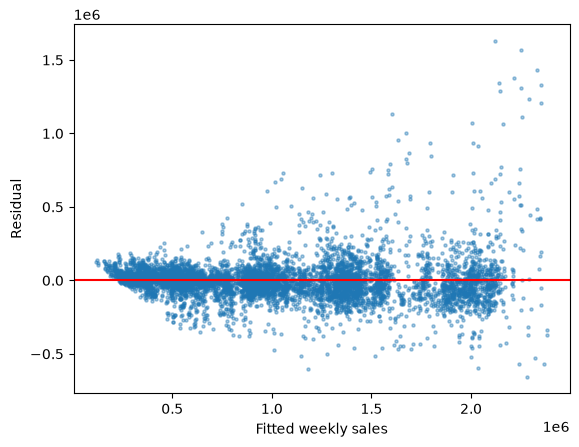

In [24]:
import matplotlib.pyplot as plt

resid = model.resid
plt.scatter(model.fittedvalues, resid, s=5, alpha=0.4)
plt.axhline(0, color='red')
plt.xlabel('Fitted weekly sales')
plt.ylabel('Residual')

In [ ]:


#  Create a log-transformed target and  last week's sales (per store)
df = df.sort_values(['store', 'date']) # sorted by time
df['weekly_sales_log'] = np.log(df['weekly_sales'])
df['sales_last_week'] = df.groupby('store')['weekly_sales'].shift(1)
df['sales_last_week_log'] = np.log(df['sales_last_week'])

# Drop rows with NaN caused by shifting the first week
df = df.dropna(subset=['sales_last_week'])

#  Rebuild feature matrix X and target y (using log sales)
features = ['holiday_flag', 'temperature', 'unemployment', 'fuel_price', 'sales_last_week_log'] + \
           [col for col in df.columns if col.startswith('month_') or col.startswith('store_')]

X = df[features]
y = df['weekly_sales_log']  # Now predicting log sales!

#  Time-based 80/20 Train/Test Split
weeks = np.sort(df["date"].unique())
cut = weeks[int(len(weeks) * 0.8)]
train = df["date"] < cut

X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]

#  Fit Linear Regression
linreg = LinearRegression().fit(X_train, y_train)
pred_log = linreg.predict(X_test)

# Convert predictions back to original dollars using np.exp() to score accurately
pred_dollars = np.exp(pred_log)
y_test_dollars = np.exp(y_test)

print("--- Out-of-Sample Performance (Log Model converted back to Dollars) ---")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_dollars, pred_dollars)):.2f}")
print(f"MAE:  {mean_absolute_error(y_test_dollars, pred_dollars):.2f}")
print(f"R2:   {r2_score(y_test_dollars, pred_dollars):.4f}")

--- Out-of-Sample Performance (Log Model converted back to Dollars) ---
RMSE: 82850.88
MAE:  54972.24
R2:   0.9759


In [31]:
df.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,month,weekly_sales_log,sales_last_week,sales_last_week_log
59,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2,14.311400,1643690.90,14.312455
116,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2,14.292966,1641957.44,14.311400
174,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2,14.158907,1611968.17,14.292966
182,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,3,14.256862,1409727.59,14.158907
268,1,2010-03-12,1439541.59,0,57.79,2.667,211.380643,8.106,3,14.179835,1554806.68,14.256862


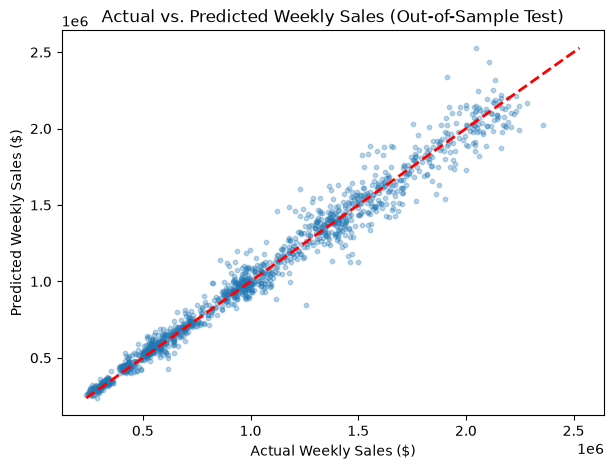

In [27]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_dollars, pred_dollars, alpha=0.3, s=10)
# Draw a perfect prediction line (y = x)
pmin = min(y_test_dollars.min(), pred_dollars.min())
pmax = max(y_test_dollars.max(), pred_dollars.max())
plt.plot([pmin, pmax], [pmin, pmax], color='red', linestyle='--', linewidth=2)

plt.xlabel("Actual Weekly Sales ($)")
plt.ylabel("Predicted Weekly Sales ($)")
plt.title("Actual vs. Predicted Weekly Sales (Out-of-Sample Test)")
plt.show()

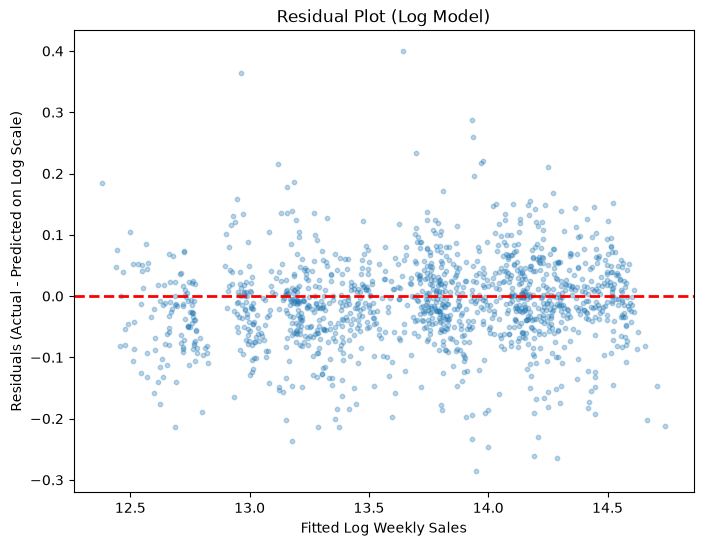

In [28]:
# Calculate residuals on the log scale (or dollar scale)
residuals_log = y_test - pred_log

plt.figure(figsize=(8, 6))
plt.scatter(pred_log, residuals_log, alpha=0.3, s=10)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.xlabel("Fitted Log Weekly Sales")
plt.ylabel("Residuals (Actual - Predicted on Log Scale)")
plt.title("Residual Plot (Log Model)")
plt.show()

/tmp/ipykernel_3336/1568995881.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature', data=top_coefs, palette='coolwarm')


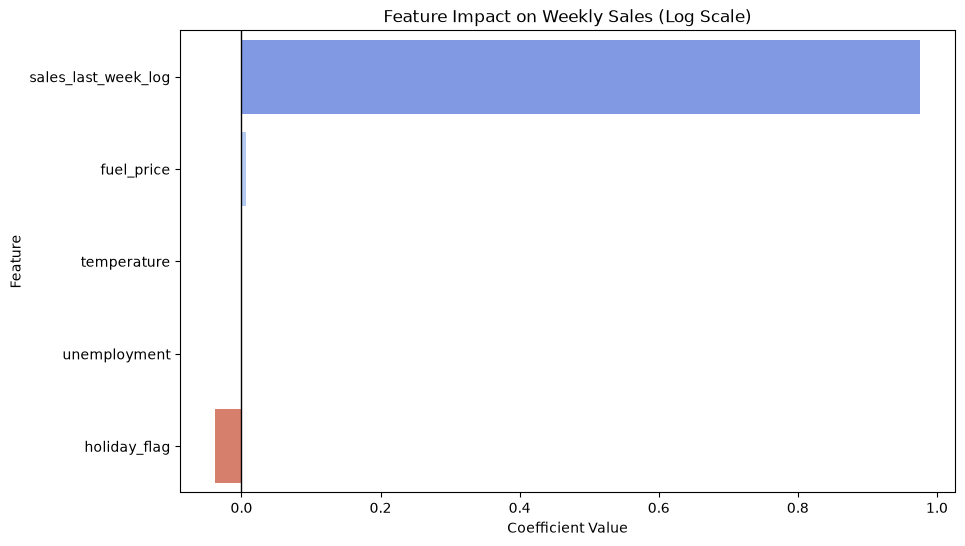

In [30]:
import seaborn as sns

coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': linreg.coef_
}).sort_values(by='Coefficient', ascending=False)

# Filter for top non-store features or plot them all
plt.figure(figsize=(10, 6))
top_coefs = pd.concat([coef_df.head(7), coef_df.tail(5)]).drop_duplicates()
sns.barplot(x='Coefficient', y='Feature', data=top_coefs, palette='coolwarm')
plt.title("Feature Impact on Weekly Sales (Log Scale)")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")
plt.axvline(0, color='black', linestyle='-', linewidth=1)
plt.show()

In [ ]:
 # saved